# Решения · handbook гл. 36

Открывай **только после** [handbook_gl36_практика.ipynb](./handbook_gl36_практика.ipynb).

Источник: [dl-optimization](https://mlhandbook-production.up.railway.app/parts/deep-learning/dl-optimization.html)


# §36.5 · Наглядно: почему инициализация критична

In [25]:
import numpy as np

np.random.seed(0)
n = 1000
x = np.random.randn(n)


def probe(scale, name, layers=10):
    a = x.copy()
    for _ in range(layers):
        W = np.random.randn(n, n) * scale
        a = np.maximum(0, W @ a)
    print(f"{name:28s}: std = {a.std():.2e}")


probe(0.1, "слишком большой (0.1)")
probe(0.01, "слишком малый (0.01)")
probe(np.sqrt(2 / n), "He √(2/n)")

слишком большой (0.1)       : std = 2.27e+03
слишком малый (0.01)        : std = 2.24e-07
He √(2/n)                   : std = 8.18e-01


# §36.3 · BatchNorm1d

In [26]:
import torch
from torch import nn

layer = nn.Sequential(nn.Linear(10, 20), nn.BatchNorm1d(20), nn.ReLU())
x = torch.randn(32, 10)
y = layer(x)
assert tuple(y.shape) == (32, 20)
print("форма выхода:", tuple(y.shape))

форма выхода: (32, 20)


# §36.6 · BN стабилизирует обучение

In [27]:
import torch
from torch import nn


def mlp(with_bn: bool, hidden: int = 64) -> nn.Module:
    layers: list[nn.Module] = [nn.Linear(10, hidden)]
    if with_bn:
        layers.append(nn.BatchNorm1d(hidden))
    layers += [nn.ReLU(), nn.Linear(hidden, hidden)]
    if with_bn:
        layers.append(nn.BatchNorm1d(hidden))
    layers += [nn.ReLU(), nn.Linear(hidden, 1)]
    return nn.Sequential(*layers)


def train_curve(model, epochs: int = 40) -> list[float]:
    torch.manual_seed(0)
    X = torch.randn(128, 10)
    y = torch.randn(128, 1)
    opt = torch.optim.Adam(model.parameters(), lr=0.05)
    lossf = nn.MSELoss()
    losses: list[float] = []
    model.train()
    for _ in range(epochs):
        opt.zero_grad()
        loss = lossf(model(X), y)
        loss.backward()
        opt.step()
        losses.append(float(loss.item()))
    return losses


loss_bn = train_curve(mlp(True))
loss_plain = train_curve(mlp(False))
print("final BN / plain:", loss_bn[-1], loss_plain[-1])
print("epoch 10 BN / plain:", loss_bn[9], loss_plain[9])
assert loss_bn[-1] < loss_plain[-1]
assert loss_bn[9] < loss_plain[9]

final BN / plain: 0.007372379302978516 0.14892767369747162
epoch 10 BN / plain: 0.5325640439987183 0.9575604200363159


# Adam vs SGD (демо)

Adam numpy vs torch: max |Δloss| = 1.29e-06


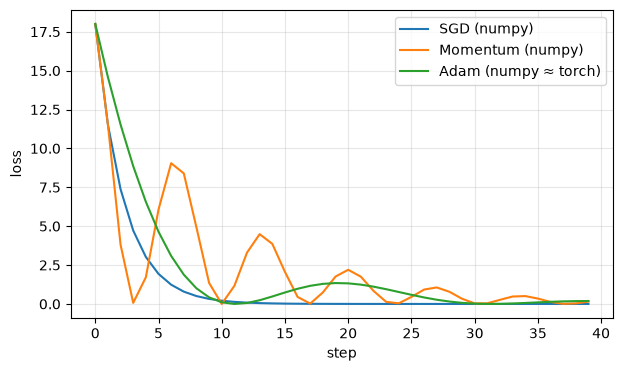

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import torch


def loss_and_grad(w):
    w = np.asarray(w, float)
    loss = w[0] ** 2 + w[1] ** 2
    grad = np.array([2 * w[0], 2 * w[1]])
    return loss, grad


w0 = np.array([3.0, 3.0])
lr = 0.1
w_sgd = w0.copy()
sgd_losses = []
for _ in range(40):
    loss, g = loss_and_grad(w_sgd)
    sgd_losses.append(loss)
    w_sgd -= lr * g

w_mom = w0.copy()
vel = np.zeros(2)
mom_losses = []
beta_m = 0.9
for _ in range(40):
    loss, g = loss_and_grad(w_mom)
    mom_losses.append(loss)
    vel = beta_m * vel + g
    w_mom -= lr * vel

m = np.zeros(2)
v = np.zeros(2)
w_adam = w0.copy()
adam_losses = []
beta1, beta2, eps, lr_a = 0.9, 0.999, 1e-8, 0.3
for t in range(1, 41):
    loss, g = loss_and_grad(w_adam)
    adam_losses.append(loss)
    m = beta1 * m + (1 - beta1) * g
    v = beta2 * v + (1 - beta2) * g**2
    w_adam -= lr_a * (m / (1 - beta1**t)) / (np.sqrt(v / (1 - beta2**t)) + eps)

wt = torch.tensor(w0, dtype=torch.float32, requires_grad=True)
opt = torch.optim.Adam([wt], lr=0.3)
torch_losses = []
for _ in range(40):
    opt.zero_grad()
    l = (wt**2).sum()
    torch_losses.append(float(l.item()))
    l.backward()
    opt.step()

adam_max_diff = max(abs(a - b) for a, b in zip(adam_losses, torch_losses))
print(f"Adam numpy vs torch: max |Δloss| = {adam_max_diff:.2e}")

plt.figure(figsize=(7, 4))
plt.plot(sgd_losses, label="SGD (numpy)")
plt.plot(mom_losses, label="Momentum (numpy)")
plt.plot(adam_losses, label="Adam (numpy ≈ torch)")
plt.legend()
plt.ylabel("loss")
plt.xlabel("step")
plt.grid(True, alpha=0.3)
plt.show()